In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../data/student-por.csv", sep=";")

# Create target categories
grade_bins = [0, 10, 14, 17, 21]

grade_labels = [
    "Poor",
    "Average",
    "Good",
    "Excellent"
]

df["Performance"] = pd.cut(
    df["G3"],
    bins=grade_bins,
    labels=grade_labels,
    right=False
)

# Separate features and target
X = df.drop(columns=["G3", "Performance"])
y = df["Performance"]

In [4]:
X_early = X.drop(columns=["G1", "G2"])
X_late = X.copy()

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_early,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (454, 30)
Validation: (97, 30)
Testing: (98, 30)


In [6]:
X_train_late = X_late.loc[X_train.index]
X_val_late = X_late.loc[X_val.index]
X_test_late = X_late.loc[X_test.index]

In [7]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

def preprocess_data(X_train, X_val, X_test):

    categorical = X_train.select_dtypes(
        include=["object"]
    ).columns.tolist()

    numerical = X_train.select_dtypes(
        include=["number"]
    ).columns.tolist()

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numerical),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
    ])

    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)

    return X_train_processed, X_val_processed, X_test_processed

In [8]:
# Early prediction
X_train_early, X_val_early, X_test_early = preprocess_data(
    X_train, X_val, X_test
)

# Late prediction
X_train_late, X_val_late, X_test_late = preprocess_data(
    X_train_late, X_val_late, X_test_late
)

print("Early feature count:", X_train_early.shape[1])
print("Late feature count:", X_train_late.shape[1])

Early feature count: 56
Late feature count: 58


C:\Users\Parv\AppData\Local\Temp\ipykernel_11544\2122530982.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X_train.select_dtypes(
C:\Users\Parv\AppData\Local\Temp\ipykernel_11544\2122530982.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-

In [9]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)

y_val_encoded = label_encoder.transform(y_val)

y_test_encoded = label_encoder.transform(y_test)

print("Class mapping:")

for i, category in enumerate(label_encoder.classes_):
    print(category, ":", i)

Class mapping:
Average : 0
Excellent : 1
Good : 2
Poor : 3


In [10]:
from sklearn.linear_model import LogisticRegression

# Early Logistic Regression
lr_early = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_early.fit(X_train_early, y_train_encoded)

lr_pred_early = lr_early.predict(X_val_early)


# Late Logistic Regression
lr_late = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_late.fit(X_train_late, y_train_encoded)

lr_pred_late = lr_late.predict(X_val_late)

In [12]:
# Load DNN predictions

dnn_predictions = np.load(
    "../models/dnn_validation_predictions.npz"
)

y_pred_dnn = dnn_predictions["y_pred_early"]
y_pred_late = dnn_predictions["y_pred_late"]

print("DNN predictions loaded successfully!")

DNN predictions loaded successfully!


In [13]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "DNN",
        "Logistic Regression",
        "DNN"
    ],

    "Scenario": [
        "Early",
        "Early",
        "Late",
        "Late"
    ],

    "Accuracy": [
        accuracy_score(y_val_encoded, lr_pred_early),
        accuracy_score(y_val_encoded, y_pred_dnn),
        accuracy_score(y_val_encoded, lr_pred_late),
        accuracy_score(y_val_encoded, y_pred_late)
    ],

    "Macro F1": [
        f1_score(y_val_encoded, lr_pred_early, average="macro"),
        f1_score(y_val_encoded, y_pred_dnn, average="macro"),
        f1_score(y_val_encoded, lr_pred_late, average="macro"),
        f1_score(y_val_encoded, y_pred_late, average="macro")
    ]
})

comparison

,Model,Scenario,Accuracy,Macro F1
0,Logistic Regression,Early,0.515464,0.343223
1,DNN,Early,0.556701,0.407293
2,Logistic Regression,Late,0.845361,0.790793
3,DNN,Late,0.835052,0.772741


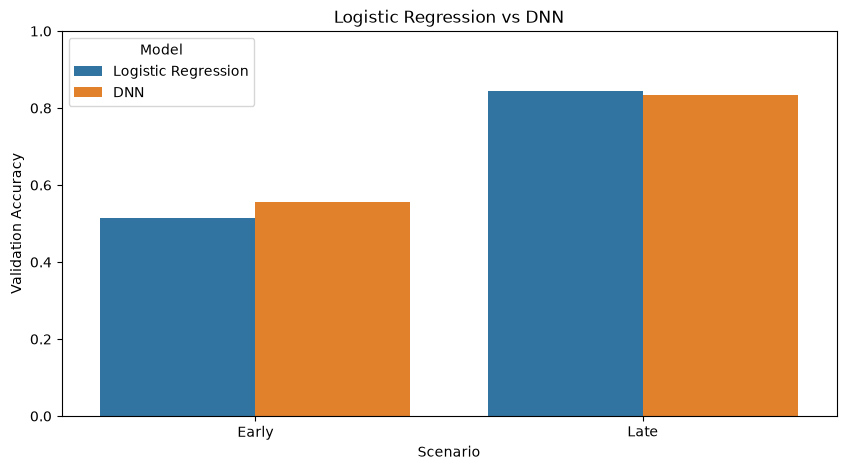

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Scenario",
    y="Accuracy",
    hue="Model"
)

plt.title("Logistic Regression vs DNN")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)

plt.show()

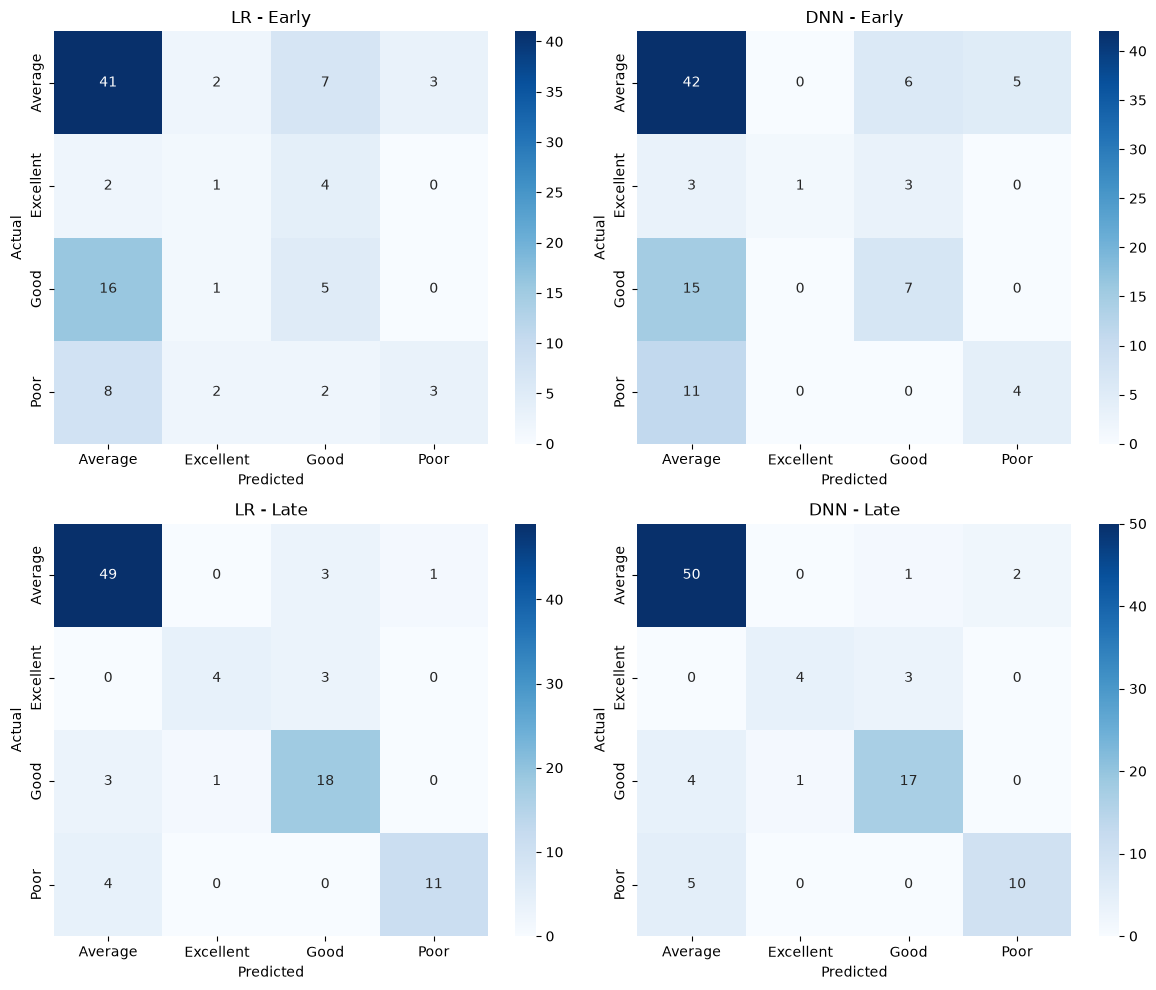

In [15]:
from sklearn.metrics import confusion_matrix

predictions = [
    ("LR - Early", lr_pred_early),
    ("DNN - Early", y_pred_dnn),
    ("LR - Late", lr_pred_late),
    ("DNN - Late", y_pred_late)
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions_model) in zip(axes.flatten(), predictions):

    cm = confusion_matrix(
        y_val_encoded,
        predictions_model
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

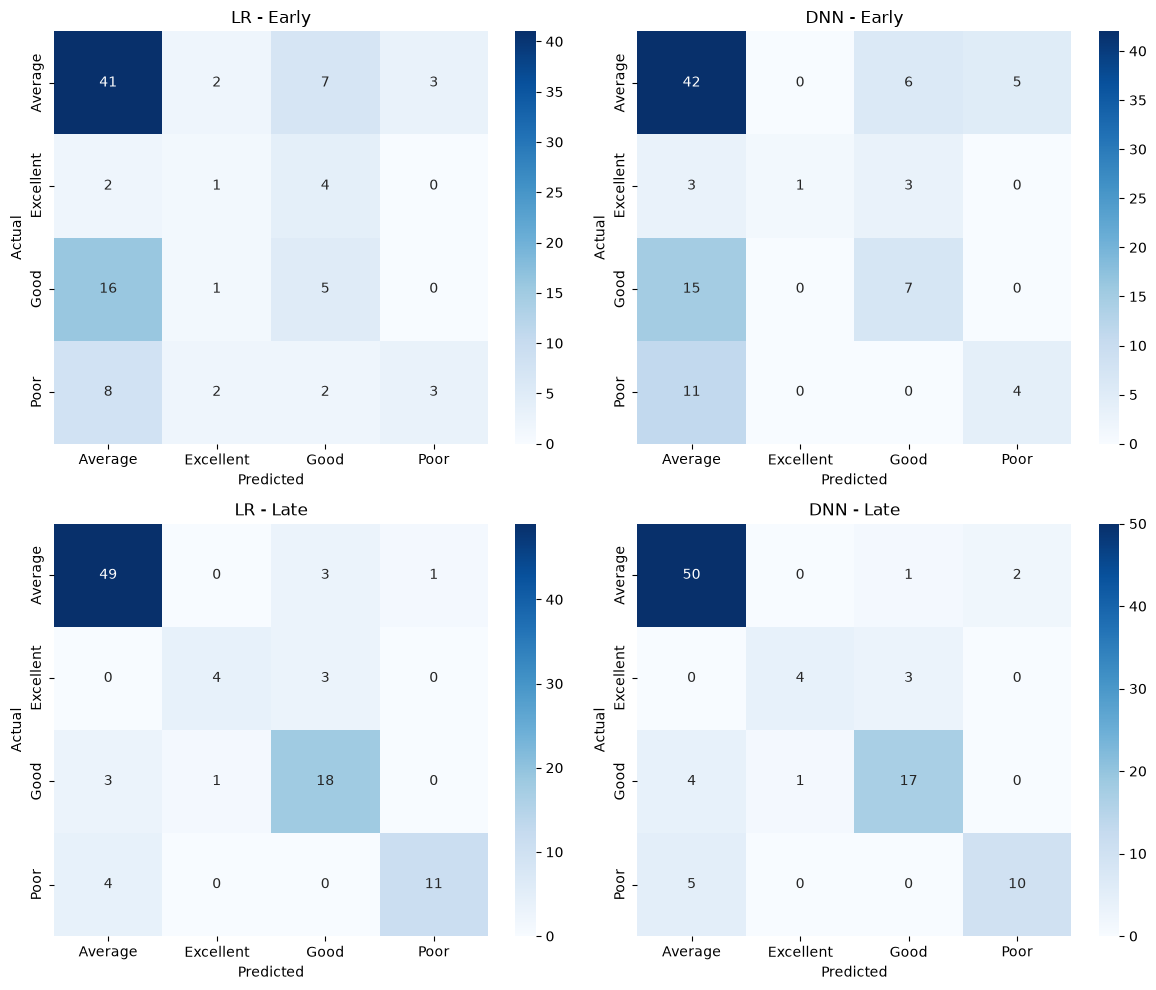

In [17]:
from sklearn.metrics import confusion_matrix

predictions = [
    ("LR - Early", lr_pred_early),
    ("DNN - Early", y_pred_dnn),
    ("LR - Late", lr_pred_late),
    ("DNN - Late", y_pred_late)
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, pred) in zip(axes.flatten(), predictions):

    cm = confusion_matrix(y_val_encoded, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [16]:
for name, pred in predictions:

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_val_encoded,
        pred,
        target_names=label_encoder.classes_,
        zero_division=0
    ))


LR - Early
              precision    recall  f1-score   support

     Average       0.61      0.77      0.68        53
   Excellent       0.17      0.14      0.15         7
        Good       0.28      0.23      0.25        22
        Poor       0.50      0.20      0.29        15

    accuracy                           0.52        97
   macro avg       0.39      0.34      0.34        97
weighted avg       0.49      0.52      0.49        97


DNN - Early
              precision    recall  f1-score   support

     Average       0.59      0.79      0.68        53
   Excellent       1.00      0.14      0.25         7
        Good       0.44      0.32      0.37        22
        Poor       0.44      0.27      0.33        15

    accuracy                           0.56        97
   macro avg       0.62      0.38      0.41        97
weighted avg       0.56      0.56      0.52        97


LR - Late
              precision    recall  f1-score   support

     Average       0.88      0.92      

In [18]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "DNN",
        "Logistic Regression",
        "DNN"
    ],

    "Scenario": [
        "Early",
        "Early",
        "Late",
        "Late"
    ],

    "Accuracy": [
        accuracy_score(y_val_encoded, lr_pred_early),
        accuracy_score(y_val_encoded, y_pred_dnn),
        accuracy_score(y_val_encoded, lr_pred_late),
        accuracy_score(y_val_encoded, y_pred_late)
    ],

    "Macro F1": [
        f1_score(y_val_encoded, lr_pred_early, average="macro"),
        f1_score(y_val_encoded, y_pred_dnn, average="macro"),
        f1_score(y_val_encoded, lr_pred_late, average="macro"),
        f1_score(y_val_encoded, y_pred_late, average="macro")
    ],

    "Weighted F1": [
        f1_score(y_val_encoded, lr_pred_early, average="weighted"),
        f1_score(y_val_encoded, y_pred_dnn, average="weighted"),
        f1_score(y_val_encoded, lr_pred_late, average="weighted"),
        f1_score(y_val_encoded, y_pred_late, average="weighted")
    ]
})

comparison

,Model,Scenario,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,Early,0.515464,0.343223,0.485354
1,DNN,Early,0.556701,0.407293,0.523283
2,Logistic Regression,Late,0.845361,0.790793,0.842862
3,DNN,Late,0.835052,0.772741,0.829841


In [19]:
comparison.to_csv(
    "../models/model_comparison.csv",
    index=False
)

print("Comparison results saved!")

Comparison results saved!
